# 04 — LLM models: GPT-2, ParsBERT, System One, Laya

The four pretrained-backbone models, evaluated **from their deployed
checkpoints through the exact serving path** (`aitextd.loaders` +
`aitextd.predictors`, one document per forward pass) on a stratified
300-document subsample of the leak-free held-out set — the CPU-budget
protocol the original trainers used. No retraining: the fine-tuning recipe is
kept below as a reference cell and stays unexecuted on this CPU-only host.

In [17]:
import gc
import json
import os

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

from aitextd import loaders, metrics, paths, plots, predictors, splits
from aitextd.system_one import typed_answers
from aitextd.text import normalize_for_pretrained

SEED = 42
EVAL_SAMPLES = 300  # CPU budget: one serving forward pass per document
RUN_TRAINING = False  # True: rerun the complete fine-tuning recipes below (GPU-host work)

torch.manual_seed(SEED)
torch.set_num_threads(8)

In [2]:
heldout = splits.deployed_heldout_frame()
sub, _ = train_test_split(
    heldout, train_size=EVAL_SAMPLES, random_state=SEED, stratify=heldout["label_binary"]
)
sub = sub.reset_index(drop=True)
y_eval = sub["label_binary"].to_numpy()
print(f"evaluation subsample: {len(sub)} documents "
      f"(human {int((y_eval == 0).sum())} / AI {int((y_eval == 1).sum())})")

evaluation subsample: 300 documents (human 144 / AI 156)


## Fine-tuning procedures (complete, flag-guarded)

The **complete** fine-tuning recipes that produced the deployed checkpoints:
GPT-2 and ParsBERT classifiers, the System One decision model (distillation
data + decision-head training) and the Laya head fine-tune with temperature
calibration.

**Not executed here** (`RUN_TRAINING = False` — transformer backward passes
need a GPU host); the evaluation cells below run unchanged either way.

In [ ]:
if RUN_TRAINING:
    # ---- shared pieces (v1 corpus, subsampling, batching) ----------------------
    import pickle

    import joblib
    import torch.nn as nn

    from aitextd.architectures import GPT2Classifier, ParsBERTClassifier
    from aitextd.training import save_checkpoint

    processed = pd.read_csv(paths.PROCESSED_CSV)
    texts = processed["text"].to_numpy()
    y = processed["aiGenerated"].to_numpy()
    indices = joblib.load(paths.DATA_DIR / "split_indices.joblib")
    train_idx, test_idx = indices["train_idx"], indices["test_idx"]

    def subsample(indices_, labels, n, seed):
        """Deterministic stratified subsample."""
        if n >= len(indices_):
            return np.asarray(indices_)
        sub, _ = train_test_split(indices_, train_size=n, random_state=seed, stratify=labels[indices_])
        return np.asarray(sub)

    def batches(items, size):
        for i in range(0, len(items), size):
            yield items[i : i + size]

    TRAIN_SUBSET, TEST_SUBSET, BATCH_SIZE, SEQ_LEN = 6000, 1500, 16, 64

    # ---- GPT-2 classifier: frozen backbone, top 4 blocks + ln_f unfrozen ------
    MODEL_FILE = "gpt2ClassifierModel.pt"
    with open(paths.GPT2_LM_MDL, "rb") as f:
        lm = pickle.load(f)
    with open(paths.GPT2_TOKENIZER_MDL, "rb") as f:
        gpt2_tok = pickle.load(f)
    gpt2_tok.pad_token = "<pad>"
    backbone = lm.transformer
    hidden_size = backbone.config.n_embd
    for p in backbone.parameters():
        p.requires_grad = False
    for block in backbone.h[-4:]:
        for p in block.parameters():
            p.requires_grad = True
    for p in backbone.ln_f.parameters():
        p.requires_grad = True

    train_sub = subsample(train_idx, y, TRAIN_SUBSET, SEED)
    torch.manual_seed(SEED)
    model = GPT2Classifier(backbone, hidden_size)
    optimizer = torch.optim.AdamW([
        {"params": [p for p in backbone.parameters() if p.requires_grad], "lr": 2e-5},
        {"params": model.head.parameters(), "lr": 1e-3},
    ])
    criterion = nn.BCEWithLogitsLoss()
    char_budget = SEQ_LEN * 8  # the pickled tokenizer is slow: pre-truncate per character

    def encode_gpt2(idx_batch):
        enc = gpt2_tok(
            [normalize_for_pretrained(str(texts[i]))[:char_budget] for i in idx_batch],
            return_tensors="pt", truncation=True, max_length=SEQ_LEN, padding="max_length",
        )
        return enc["input_ids"], enc["attention_mask"], torch.tensor(y[idx_batch], dtype=torch.float32)

    model.train()
    order = train_sub.copy()
    np.random.default_rng(SEED + 1).shuffle(order)
    for step, idx_batch in enumerate(batches(order, BATCH_SIZE), start=1):
        input_ids, attention_mask, labels = encode_gpt2(idx_batch)
        optimizer.zero_grad()
        loss = criterion(model(input_ids, attention_mask), labels)
        loss.backward()
        optimizer.step()
        if step % 50 == 0:
            print(f"gpt2 step {step} loss={loss.item():.4f}", flush=True)
    save_checkpoint(paths.model_path(MODEL_FILE), model, config={
        "seq_len": SEQ_LEN, "hidden_size": hidden_size, "n_layer": backbone.config.n_layer,
        "vocab_size": backbone.config.vocab_size, "n_head": backbone.config.n_head,
    })
    del model, backbone, lm
    gc.collect()

    # ---- ParsBERT classifier: frozen encoder, top 4 layers + pooler unfrozen --
    from transformers import AutoModel, AutoTokenizer

    BACKBONE_NAME = "HooshvareLab/bert-fa-base-uncased"
    MODEL_FILE = "parsbertClassifierModel.pt"
    tokenizer = AutoTokenizer.from_pretrained(BACKBONE_NAME)
    backbone = AutoModel.from_pretrained(BACKBONE_NAME)
    hidden_size = backbone.config.hidden_size
    for p in backbone.parameters():
        p.requires_grad = False
    for layer in backbone.encoder.layer[-4:]:
        for p in layer.parameters():
            p.requires_grad = True
    for p in backbone.pooler.parameters():
        p.requires_grad = True

    train_sub = subsample(train_idx, y, TRAIN_SUBSET, SEED)
    test_sub = subsample(test_idx, y, TEST_SUBSET, SEED)
    needed = np.concatenate([train_sub, test_sub])
    normed = {int(i): normalize_for_pretrained(str(texts[i])) for i in needed}
    torch.manual_seed(SEED)
    model = ParsBERTClassifier(backbone, hidden_size)
    optimizer = torch.optim.AdamW([
        {"params": [p for p in backbone.parameters() if p.requires_grad], "lr": 2e-5},
        {"params": model.head.parameters(), "lr": 1e-3},
    ], weight_decay=0.01)

    def encode_bert(idx_batch):
        enc = tokenizer(
            [normed[int(i)] for i in idx_batch],
            return_tensors="pt", truncation=True, max_length=SEQ_LEN, padding="max_length",
        )
        return enc["input_ids"], enc["attention_mask"], torch.tensor(y[idx_batch], dtype=torch.float32)

    model.train()
    order = train_sub.copy()
    np.random.default_rng(SEED + 1).shuffle(order)
    for step, idx_batch in enumerate(batches(order, BATCH_SIZE), start=1):
        input_ids, attention_mask, labels = encode_bert(idx_batch)
        optimizer.zero_grad()
        loss = criterion(model(input_ids, attention_mask), labels)
        loss.backward()
        optimizer.step()
        if step % 50 == 0:
            print(f"parsbert step {step} loss={loss.item():.4f}", flush=True)
    backbone_config = backbone.config.to_dict()
    save_checkpoint(paths.model_path(MODEL_FILE), model, config={
        "seq_len": SEQ_LEN, "hidden_size": hidden_size,
        "n_layer": backbone.config.num_hidden_layers, "backbone_config": backbone_config,
    })
    tokenizer.save_pretrained(paths.PARSBERT_TOKENIZER_DIR)
    del model, backbone
    gc.collect()
    print("gpt2 + parsbert checkpoints saved")
else:
    print("RUN_TRAINING=False — the deployed checkpoints are used below")

### System One procedure (complete, flag-guarded)

The **complete** two-step System One build: (1) distill soft targets from the
GPT-2 teacher into JSONL records, (2) train the ParsBERT-backed decision model
with soft cross-entropy over choice / score / review heads. **Not executed
here** (`RUN_TRAINING = False`).

In [ ]:
if RUN_TRAINING:
    # ---- System One: distillation data + decision-head training ---------------
    from itertools import pairwise

    from transformers import AutoModel, BertConfig

    from aitextd.architectures import ParsBERTClassifier, SystemOneDecisionModel
    from aitextd.constants import SYSTEM_ONE_CHOICE_CANDIDATES, SYSTEM_ONE_SCORE_LEVELS
    from aitextd.constants import (
        SYSTEM_ONE_CHOICE_CANDIDATES_FA, SYSTEM_ONE_SCORE_LEVELS_FA,
    )
    from aitextd.loaders import get_parsbert_tokenizer

    S1_DATA = paths.DATA_DIR / "system_one_data"
    QUESTIONS = {
        "source": {"type": "choice", "candidates": SYSTEM_ONE_CHOICE_CANDIDATES, "candidatesFa": SYSTEM_ONE_CHOICE_CANDIDATES_FA},
        "ai_level": {"type": "score", "levels": SYSTEM_ONE_SCORE_LEVELS, "levelsFa": SYSTEM_ONE_SCORE_LEVELS_FA},
        "needs_review": {"type": "noul"},
    }
    LABEL_WEIGHT, TEACHER_WEIGHT = 0.8, 0.2
    CHOICE_CLIP, SCORE_SIGMA, NOUL_BAND = (0.02, 0.98), 0.9, (0.15, 0.85)

    def subsample(indices_, labels, n, seed):
        if n >= len(indices_):
            return np.asarray(indices_)
        sub, _ = train_test_split(indices_, train_size=n, random_state=seed, stratify=labels[indices_])
        return np.asarray(sub)

    def batches(items_, size):
        for i in range(0, len(items_), size):
            yield items_[i : i + size]

    # ---- step 1: distill soft targets from the GPT-2 teacher ------------------
    from aitextd.loaders import get_gpt2_tokenizer, load_gpt2_backbone

    teacher_ckpt = torch.load(paths.model_path("gpt2ClassifierModel.pt"), map_location="cpu", weights_only=False)
    teacher = GPT2Classifier(load_gpt2_backbone(), hidden_size=teacher_ckpt["config"]["hidden_size"])
    teacher.load_state_dict(teacher_ckpt["state_dict"])
    teacher.eval()
    tok = get_gpt2_tokenizer()
    char_budget = teacher_ckpt["config"]["seq_len"] * 8

    def teacher_probs(raw_texts):
        out = []
        with torch.no_grad():
            for batch in batches(raw_texts, 32):
                enc = tok(
                    [normalize_for_pretrained(str(t))[:char_budget] for t in batch],
                    return_tensors="pt", truncation=True,
                    max_length=teacher_ckpt["config"]["seq_len"], padding="max_length",
                )
                out.append(torch.sigmoid(teacher(enc["input_ids"], enc["attention_mask"])).numpy())
        return np.concatenate(out)

    def build_records(indices_, split_name):
        p_teacher = teacher_probs(texts[indices_])
        records = []
        for k, i in enumerate(indices_):
            t_ai = min(max(LABEL_WEIGHT * float(y[i]) + TEACHER_WEIGHT * float(p_teacher[k]), *CHOICE_CLIP), 1.0)
            center = (len(SYSTEM_ONE_SCORE_LEVELS) - 1) * t_ai
            levels = np.arange(len(SYSTEM_ONE_SCORE_LEVELS), dtype=float)
            score_t = np.exp(-((levels - center) ** 2) / (2 * SCORE_SIGMA**2))
            score_t = score_t / score_t.sum()
            records.append({
                "id": f"{split_name}-{i:06d}", "split": split_name, "label": int(y[i]),
                "state": {"text": str(texts[i])}, "questions": QUESTIONS, "teacher": "gpt2_transformer",
                "targets": {
                    "source": {"human_written": round(1 - t_ai, 4), "ai_generated": round(t_ai, 4)},
                    "ai_level": [round(float(p), 4) for p in score_t],
                    "needs_review": 1.0 if NOUL_BAND[0] <= p_teacher[k] <= NOUL_BAND[1] else 0.0,
                },
                "teacherAiProbability": round(float(p_teacher[k]), 4),
            })
        return records

    S1_DATA.mkdir(parents=True, exist_ok=True)
    train_sub = subsample(train_idx, y, TRAIN_SUBSET, SEED)
    test_sub = subsample(test_idx, y, TEST_SUBSET, SEED)
    for name, sub in (("train", train_sub), ("test", test_sub)):
        with open(S1_DATA / f"system_one_{name}.jsonl", "w", encoding="utf-8") as f:
            for record in build_records(sub, name):
                f.write(json.dumps(record, ensure_ascii=False) + "\n")
        print(f"{name}: wrote {len(sub)} records")
    del teacher
    gc.collect()

    # ---- step 2: train the ParsBERT-backed decision model on the JSONL --------
    def load_jsonl(path):
        return [json.loads(line) for line in open(path, encoding="utf-8") if line.strip()]

    train_records = load_jsonl(S1_DATA / "system_one_train.jsonl")
    test_records = load_jsonl(S1_DATA / "system_one_test.jsonl")
    choice_t = np.array([[r["targets"]["source"][c] for c in SYSTEM_ONE_CHOICE_CANDIDATES] for r in train_records], dtype=np.float32)
    score_t = np.array([r["targets"]["ai_level"] for r in train_records], dtype=np.float32)
    noul_t = np.array([r["targets"]["needs_review"] for r in train_records], dtype=np.float32)
    y_test_s1 = np.array([r["label"] for r in test_records])
    normed = [normalize_for_pretrained(r["state"]["text"]) for r in train_records]
    normed_test = [normalize_for_pretrained(r["state"]["text"]) for r in test_records]

    base_ckpt = torch.load(paths.model_path("parsbertClassifierModel.pt"), map_location="cpu", weights_only=False)
    backbone = AutoModel.from_config(BertConfig.from_dict(base_ckpt["config"]["backbone_config"]))
    classifier = ParsBERTClassifier(backbone, base_ckpt["config"]["hidden_size"])
    classifier.load_state_dict(base_ckpt["state_dict"])
    backbone = classifier.backbone  # fine-tuned classification knowledge stays intact
    hidden_size = backbone.config.hidden_size
    for p in backbone.parameters():
        p.requires_grad = False
    for layer in backbone.encoder.layer[-4:]:
        for p in layer.parameters():
            p.requires_grad = True

    torch.manual_seed(SEED)
    model = SystemOneDecisionModel(
        backbone, hidden_size,
        n_choice=len(SYSTEM_ONE_CHOICE_CANDIDATES),
        n_score_levels=len(SYSTEM_ONE_SCORE_LEVELS),
        pool_on_cls=True,
    )
    optimizer = torch.optim.AdamW([
        {"params": [p for p in backbone.parameters() if p.requires_grad], "lr": 2e-5},
        {"params": model.choice_head.parameters(), "lr": 1e-3},
        {"params": model.score_head.parameters(), "lr": 1e-3},
        {"params": model.noul_head.parameters(), "lr": 1e-3},
    ], weight_decay=0.01)

    def soft_ce(logits, target_probs):
        return -(target_probs * torch.log_softmax(logits, dim=-1)).sum(dim=-1).mean()

    def encode_s1(batch_texts):
        return get_parsbert_tokenizer()(
            batch_texts, return_tensors="pt", truncation=True, max_length=SEQ_LEN, padding="max_length"
        )

    model.train()
    for epoch in (1, 2, 3):
        order = np.arange(len(train_records))
        np.random.default_rng(SEED + epoch).shuffle(order)
        for step, idx_batch in enumerate(batches(order, BATCH_SIZE), start=1):
            enc = encode_s1([normed[i] for i in idx_batch])
            choice_logits, score_logits, noul_logit = model(enc["input_ids"], enc["attention_mask"])
            loss = (
                soft_ce(choice_logits, torch.from_numpy(choice_t[idx_batch]))
                + 0.5 * soft_ce(score_logits, torch.from_numpy(score_t[idx_batch]))
                + 0.5 * nn.functional.binary_cross_entropy_with_logits(noul_logit, torch.from_numpy(noul_t[idx_batch]))
            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if step % 50 == 0:
                print(f"s1 epoch {epoch} step {step} loss={loss.item():.4f}", flush=True)

    model.eval()
    choice_probs_all = []
    with torch.no_grad():
        for idx_batch in batches(np.arange(len(test_records)), 32):
            enc = encode_s1([normed_test[i] for i in idx_batch])
            choice_logits, _, _ = model(enc["input_ids"], enc["attention_mask"])
            choice_probs_all.append(torch.softmax(choice_logits, dim=-1).numpy())
    choice_probs = np.concatenate(choice_probs_all)
    s1_metrics = metrics.evaluate(y_test_s1, choice_probs[:, 1])
    backbone_config = backbone.config.to_dict()
    torch.save({
        "state_dict": model.state_dict(),
        "config": {
            "seq_len": SEQ_LEN, "hidden_size": hidden_size,
            "n_choice": len(SYSTEM_ONE_CHOICE_CANDIDATES),
            "n_score_levels": len(SYSTEM_ONE_SCORE_LEVELS),
            "choice_candidates": SYSTEM_ONE_CHOICE_CANDIDATES,
            "score_levels": SYSTEM_ONE_SCORE_LEVELS,
            "thresholds": {"proceed": 0.8, "needsReview": 0.6},
            "backbone_config": backbone_config,
        },
        "metrics": metrics.registry_metrics(s1_metrics),
    }, paths.model_path("systemOneModel.pt"))
    del model, backbone, classifier
    gc.collect()
    print("systemOneModel.pt saved:", s1_metrics["f1"])
else:
    print("RUN_TRAINING=False — the deployed systemOneModel.pt is used below")

### Laya fine-tune procedure (complete, flag-guarded)

The **complete** Laya head fine-tune: System One JSONL targets -> laya item
collections -> frozen-encoder head training with noisy-candidate rewards and
gradient accumulation -> per-question temperature calibration (LBFGS) ->
safetensors + config export. **Not executed here** (`RUN_TRAINING = False`).

In [ ]:
if RUN_TRAINING:
    # ---- Laya head fine-tune (RLCD-style) + per-question temperature calibration
    import random

    from safetensors.torch import load_file, save_file
    from transformers import AutoTokenizer

    from laya.agent import _fix_tokenizer_config
    from laya.common import (
        QTYPES, TEMP_MAX, TEMP_MIN, build_model, build_sequence,
        proper_reward, render_options, state_room,
    )

    QUESTION_TARGETS = {
        "source": ("source", "choice"),
        "machine_likeness": ("ai_level", "score"),
        "needs_review": ("needs_review", "noul"),
    }
    RECORDS, CALIB_RECORDS, TEST_RECORDS = 1200, 200, 400
    EPOCHS, MICRO_BATCH, GRAD_ACCUM = 2, 4, 8
    LR_HEAD, MAX_LEN, LAYA_SEED = 1e-4, 512, 20261005
    base_dir = paths.LAYA_BASE_DIR
    _fix_tokenizer_config(str(base_dir))

    laya_cfg = json.load(open(base_dir / "rl_agent_config.json"))
    laya_cfg["max_len"] = MAX_LEN
    laya_cfg.setdefault("head_max_len", 256)
    tokenizer_l = AutoTokenizer.from_pretrained(base_dir / "tokenizer")

    def internal_question(qid):
        q = SYSTEM_ONE_DETECTION_QUESTIONS[qid]
        crit = q.get("criteria")
        if q["type"] == "choice" and isinstance(crit, list):
            crit = {c: None for c in crit}
        return {"t": q["type"], "ins": q["instructions"], "crit": crit}

    def target_distribution(record, qid):
        key, qtype = QUESTION_TARGETS[qid]
        value = record["targets"][key]
        if qtype == "choice":
            row = [float(value[c]) for c in ("human_written", "ai_generated")]
        elif qtype == "score":
            row = [float(p) for p in value]
        else:
            row = [1.0 - float(value), float(value)]  # noul renders [false, true]
        total = sum(row)
        return [x / total for x in row] if total > 0 else [1.0 / len(row)] * len(row)

    def build_items(records, qids):
        internal = {qid: internal_question(qid) for qid in qids}
        items = []
        for record in records:
            text = str(record["state"]["text"])
            for qid in qids:
                q = internal[qid]
                room = state_room(tokenizer_l, q, MAX_LEN, laya_cfg["head_max_len"])
                sequence, markers = build_sequence(
                    tokenizer_l, {"text": text[: max(128, room * 4)]}, q, MAX_LEN, laya_cfg["head_max_len"]
                )
                if len(markers) == len(render_options(q)):
                    items.append({
                        "ids": sequence, "markers": markers, "qtype": QTYPES[q["t"]],
                        "target": target_distribution(record, qid), "label": int(record["label"]),
                    })
        return items

    def stratified(records, n, seed):
        if n >= len(records):
            return records
        idx, _ = train_test_split(range(len(records)), train_size=n, random_state=seed,
                                  stratify=[r["label"] for r in records])
        return [records[i] for i in sorted(idx)]

    def load_jsonl(path):
        return [json.loads(line) for line in open(path, encoding="utf-8") if line.strip()]

    train_records = stratified(load_jsonl(S1_DATA / "system_one_train.jsonl"), RECORDS, SEED)
    calib_records = stratified(load_jsonl(S1_DATA / "system_one_train.jsonl"), CALIB_RECORDS, SEED + 1)
    train_records = [r for r in train_records if r["id"] not in {c["id"] for c in calib_records}]
    test_records = stratified(load_jsonl(S1_DATA / "system_one_test.jsonl"), TEST_RECORDS, SEED)
    qids = list(QUESTION_TARGETS)
    items = {name: build_items(recs, qids) for name, recs in (("train", train_records), ("calib", calib_records), ("test", test_records))}
    print({name: len(v) for name, v in items.items()})

    model = build_model(laya_cfg, encoder_dir=base_dir / "encoder")
    model.load_state_dict(load_file(str(base_dir / "model.safetensors")), strict=True)
    model.float()
    for p in model.encoder.parameters():
        p.requires_grad = False
    model.to("cpu").train()

    def collate(chunk):
        size, seq_len = len(chunk), max(len(it["ids"]) for it in chunk)
        kmax = max(len(it["markers"]) for it in chunk)
        ids = torch.full((size, seq_len), tokenizer_l.pad_token_id, dtype=torch.long)
        attention = torch.zeros((size, seq_len), dtype=torch.long)
        positions = torch.zeros((size, kmax), dtype=torch.long)
        mask = torch.zeros((size, kmax), dtype=torch.bool)
        target = torch.zeros((size, kmax), dtype=torch.float32)
        for i, it in enumerate(chunk):
            ids[i, : len(it["ids"])] = torch.tensor(it["ids"])
            attention[i, : len(it["ids"])] = 1
            positions[i, : len(it["markers"])] = torch.tensor(it["markers"])
            mask[i, : len(it["markers"])] = True
            target[i, : len(it["target"])] = torch.tensor(it["target"])
        return ids, attention, positions, mask, target, torch.tensor([it["qtype"] for it in chunk])

    head_params = [p for n, p in model.named_parameters() if "encoder." not in n]
    optimizer = torch.optim.AdamW(head_params, lr=LR_HEAD, weight_decay=0.01)
    train_items = items["train"]
    random.Random(LAYA_SEED).shuffle(train_items)
    for epoch in range(EPOCHS):
        random.Random(SEED + epoch).shuffle(train_items)
        optimizer.zero_grad(set_to_none=True)
        for start in range(0, len(train_items), MICRO_BATCH):
            chunk = train_items[start : start + MICRO_BATCH]
            ids, attention, positions, mask, target, qtype = collate(chunk)
            logits, activation = model(ids, attention, positions, mask, qtype, detach_encoder=True)
            logits = logits.float()
            k = mask.sum(-1, keepdim=True).float()
            sigma = 0.4 + (0.1 - 0.4) * epoch / max(1, EPOCHS - 1)
            eps = torch.randn((4, *logits.shape)) * sigma * mask
            eps = (eps - eps.sum(-1, keepdim=True) / k) * mask
            noisy = logits.detach().unsqueeze(0) + eps
            probs = torch.softmax(noisy.masked_fill(~mask, -1e4), -1)
            with torch.no_grad():
                reward = proper_reward(probs, target.unsqueeze(0), qtype, mask, w_sph=0.75, w_rps=1.0)
            advantage = (reward - reward.mean(0, keepdim=True)) / (reward.std() + 1e-6)
            logp = -(((noisy - logits.unsqueeze(0)) ** 2) * mask).sum(-1) / (2 * sigma**2)
            loss = (
                -(advantage * logp).mean()
                - (target * torch.log_softmax(logits.masked_fill(~mask, -1e4), -1)).sum(-1).mean()
                + 0.0 * activation.sum()
            ) / GRAD_ACCUM
            loss.backward()
            if (start // MICRO_BATCH + 1) % GRAD_ACCUM == 0 or start + MICRO_BATCH >= len(train_items):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

    model.eval()
    samples = [[] for _ in range(3)]
    with torch.no_grad():
        for start in range(0, len(items["calib"]), MICRO_BATCH):
            ids, attention, positions, mask, _, qtype = collate(items["calib"][start : start + MICRO_BATCH])
            logits, _ = model(ids, attention, positions, mask, qtype, detach_encoder=True)
            for i, it in enumerate(items["calib"][start : start + MICRO_BATCH]):
                samples[it["qtype"]].append((logits[i, : len(it["markers"])].float(), it["target"]))

    def fit_temperature(group):
        if len(group) < 10:
            return 1.0
        kmax = max(len(l) for l, _ in group)
        logits = torch.full((len(group), kmax), -1e4)
        targets = torch.zeros((len(group), kmax))
        for i, (values, tgt) in enumerate(group):
            logits[i, : len(values)] = values
            targets[i, : len(tgt)] = torch.as_tensor(tgt, dtype=torch.float32)
        log_t = torch.zeros(1, requires_grad=True)
        opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)

        def closure():
            opt.zero_grad()
            loss = -(targets * torch.log_softmax(logits / log_t.exp(), -1)).sum(-1).mean()
            loss.backward()
            return loss

        opt.step(closure)
        return float(torch.clamp(log_t.exp(), TEMP_MIN, TEMP_MAX).item())

    temperatures = [fit_temperature(g) if g else 1.2 for g in samples]
    laya_cfg.update({
        "fine_tuned": True, "model_name": "laya-persian", "temperature": temperatures,
        "training": {
            "epochs_completed": EPOCHS, "train_items": len(train_items),
            "calib_items": len(items["calib"]), "test_items": len(items["test"]),
            "max_len": MAX_LEN, "mode": "head_only", "base": "convaiinnovations/laya [multilingual]",
            "fine_tuned_from_checkpoint": True, "data": "system_one JSONL (GPT-2-distilled soft targets)",
        },
    })
    laya_cfg.pop("temperature_by_options", None)
    out_dir = paths.LAYA_OUTPUT_DIR
    out_dir.mkdir(parents=True, exist_ok=True)
    save_file(
        {n: v.detach().half().cpu().contiguous() for n, v in model.state_dict().items()},
        str(out_dir / "model.safetensors"),
    )
    model.encoder.config.save_pretrained(out_dir / "encoder")
    tokenizer_l.save_pretrained(out_dir / "tokenizer")
    with open(out_dir / "rl_agent_config.json", "w") as f:
        json.dump(laya_cfg, f, indent=2)
    with open(out_dir / "metrics.json", "w") as f:
        json.dump({"temperatures": temperatures}, f, indent=2)
    del model
    gc.collect()
    print("laya_persian saved; temperatures:", [round(t, 4) for t in temperatures])
else:
    print("RUN_TRAINING=False — the deployed laya_persian is used below")

## Evaluation of the deployed checkpoints (serving path)

In [3]:
reports, probs_held, bundles = {}, {}, {}

RUNTIMES = {
    "gpt2_transformer": ("pytorch-gpt2", "gpt2ClassifierModel.pt"),
    "parsbert": ("pytorch-parsbert", "parsbertClassifierModel.pt"),
    "system_one": ("pytorch-system-one", "systemOneModel.pt"),
    "laya": ("pytorch-laya", None),  # loads from models/laya_persian
}


def serving_probs(model_id, frame):
    """AI probabilities through the exact serving path: loaders -> predictors,
    one document per forward pass."""
    runtime, filename = RUNTIMES[model_id]
    bundle = loaders.LOADERS[runtime]({"filename": filename} if filename else {})
    probs = []
    for text in frame["text"].astype(str):
        cleaned = normalize_for_pretrained(text)
        result = predictors.PREDICTORS[runtime](bundle, text, cleaned, {})
        probs.append(result["aiProbability"] if isinstance(result, dict) else float(result))
        if len(probs) % 60 == 0:
            print(f"  {len(probs)}/{len(frame)} scored", flush=True)
    return np.asarray(probs), bundle

In [4]:
probs_held["gpt2_transformer"], bundles["gpt2_transformer"] = serving_probs("gpt2_transformer", sub)
reports["gpt2_transformer"] = metrics.evaluation_report(y_eval, probs_held["gpt2_transformer"])
print("gpt2_transformer AUROC/F1/ECE:", reports["gpt2_transformer"]["roc_auc"],
      reports["gpt2_transformer"]["f1"], reports["gpt2_transformer"]["ece"])
gc.collect()

  60/300 scored
  120/300 scored
  180/300 scored
  240/300 scored
  300/300 scored
gpt2_transformer AUROC/F1/ECE: 1.0 1.0 0.0007


0

In [5]:
probs_held["parsbert"], bundles["parsbert"] = serving_probs("parsbert", sub)
reports["parsbert"] = metrics.evaluation_report(y_eval, probs_held["parsbert"])
print("parsbert AUROC/F1/ECE:", reports["parsbert"]["roc_auc"],
      reports["parsbert"]["f1"], reports["parsbert"]["ece"])
gc.collect()

  60/300 scored
  120/300 scored
  180/300 scored
  240/300 scored
  300/300 scored
parsbert AUROC/F1/ECE: 1.0 1.0 0.0


33

In [6]:
probs_held["system_one"], bundles["system_one"] = serving_probs("system_one", sub)
reports["system_one"] = metrics.evaluation_report(y_eval, probs_held["system_one"])
print("system_one AUROC/F1/ECE:", reports["system_one"]["roc_auc"],
      reports["system_one"]["f1"], reports["system_one"]["ece"])
gc.collect()

  60/300 scored
  120/300 scored
  180/300 scored
  240/300 scored
  300/300 scored
system_one AUROC/F1/ECE: 0.9995 0.9904 0.013


0

In [7]:
SAMPLES = [
    "دیروز رفتم بازار تا برای عید نوروز خرید کنم. شلوغ بود و صف طولی بسته بودیم تا نان بگیریم.",
    "هوش مصنوعی یکی از مهم‌ترین فناوری‌های قرن بیست‌ویکم است. این فناوری تأثیر عمیقی بر اقتصاد گذاشته است.",
]
for text in SAMPLES:
    cleaned = normalize_for_pretrained(text)
    answers = typed_answers(
        bundles["system_one"], predictors.predict_system_one(bundles["system_one"], text, cleaned, {})
    )
    print(f"system_one: choice={answers.choice.answer} score={answers.score.value:.2f} review={answers.noul.answer}")

system_one: choice=human_written score=0.54 review=False
system_one: choice=ai_generated score=3.55 review=False


In [8]:
probs_held["laya"], bundles["laya"] = serving_probs("laya", sub)
reports["laya"] = metrics.evaluation_report(y_eval, probs_held["laya"])
print("laya AUROC/F1/ECE:", reports["laya"]["roc_auc"], reports["laya"]["f1"], reports["laya"]["ece"])
for text in SAMPLES:
    cleaned = normalize_for_pretrained(text)
    answers = typed_answers(bundles["laya"], predictors.predict_laya(bundles["laya"], text, cleaned, {}))
    print(f"laya: choice={answers.choice.answer} score={answers.score.value:.2f} review={answers.noul.answer}")
gc.collect()

  60/300 scored
  120/300 scored
  180/300 scored
  240/300 scored
  300/300 scored
laya AUROC/F1/ECE: 0.9773 0.4162 0.3513
laya: choice=human_written score=0.46 review=False
laya: choice=human_written score=0.48 review=False


0

In [20]:
metrics.evaluation_table(reports, metrics.RANKING_COLUMNS)

,roc_auc,pr_auc,pauc_5,tpr_at_fpr_1,tpr_at_fpr_5,fpr_at_tpr_90
model,,,,,,
gpt2_transformer,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
parsbert,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
system_one,0.9995,0.9996,0.9909,0.9936,0.9936,0.0000
laya,0.9773,0.9869,0.9341,0.9231,0.9679,0.0069


In [10]:
metrics.evaluation_table(reports, metrics.THRESHOLD_COLUMNS)

,accuracy,balanced_accuracy,macro_f1,mcc,kappa,precision,recall,f1,fpr
model,,,,,,,,,
gpt2_transformer,1.0000,1.0000,1.0000,1.0000,1.000,1.0000,1.0000,1.0000,0.0000
parsbert,1.0000,1.0000,1.0000,1.0000,1.000,1.0000,1.0000,1.0000,0.0000
system_one,0.9900,0.9901,0.9900,0.9800,0.980,0.9935,0.9872,0.9904,0.0069
laya,0.6167,0.6314,0.5654,0.3823,0.255,1.0000,0.2628,0.4162,0.0000


In [11]:
metrics.evaluation_table(reports, metrics.CALIBRATION_COLUMNS)

,ece,ace,mce,brier,nll,calibration_slope,calibration_intercept
model,,,,,,,
gpt2_transformer,0.0007,0.0006,0.1946,0.0001,0.0008,2.3957,1.1354
parsbert,0.0000,0.0000,0.0001,0.0000,0.0000,1.1923,-0.0227
system_one,0.0130,0.0156,0.6233,0.0084,0.0459,1.2656,0.4578
laya,0.3513,0.3611,0.9103,0.2823,0.9010,10.4640,38.5977


<Axes: title={'left': 'LLM family — held-out subsample (serving path)'}>

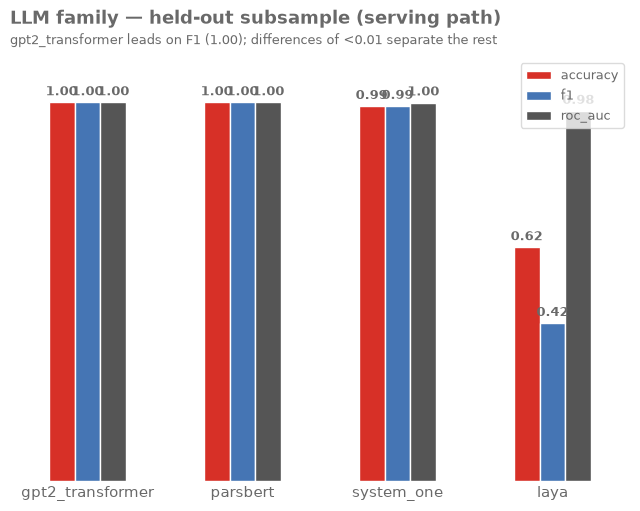

In [12]:
plots.metric_bars(reports, "LLM family — held-out subsample (serving path)")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


<Axes: title={'center': 'gpt2_transformer'}, xlabel='prediction'>

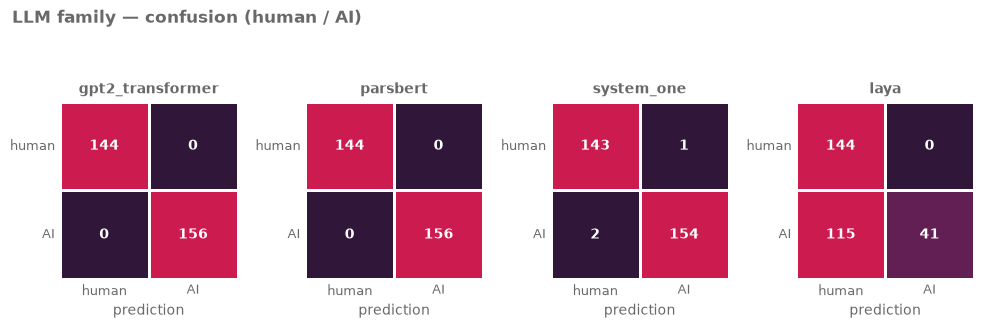

In [13]:
plots.confusion_grid(reports, "LLM family — confusion (human / AI)")

<Axes: title={'left': 'LLM family — ROC, low-FPR region'}, xlabel='False Positive Rate (log scale)', ylabel='True Positive Rate'>

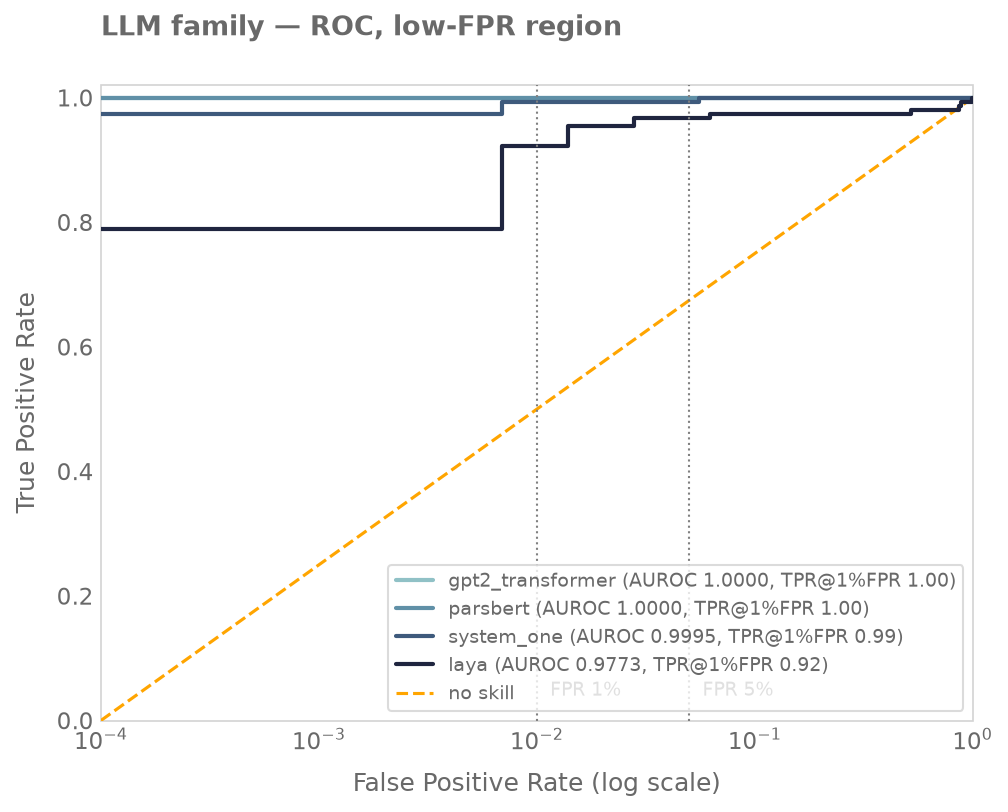

In [14]:
plots.roc_curves_log(y_eval, probs_held, "LLM family — ROC, low-FPR region")

<Axes: title={'left': 'gpt2_transformer\nECE 0.001'}, ylabel='empirical accuracy'>

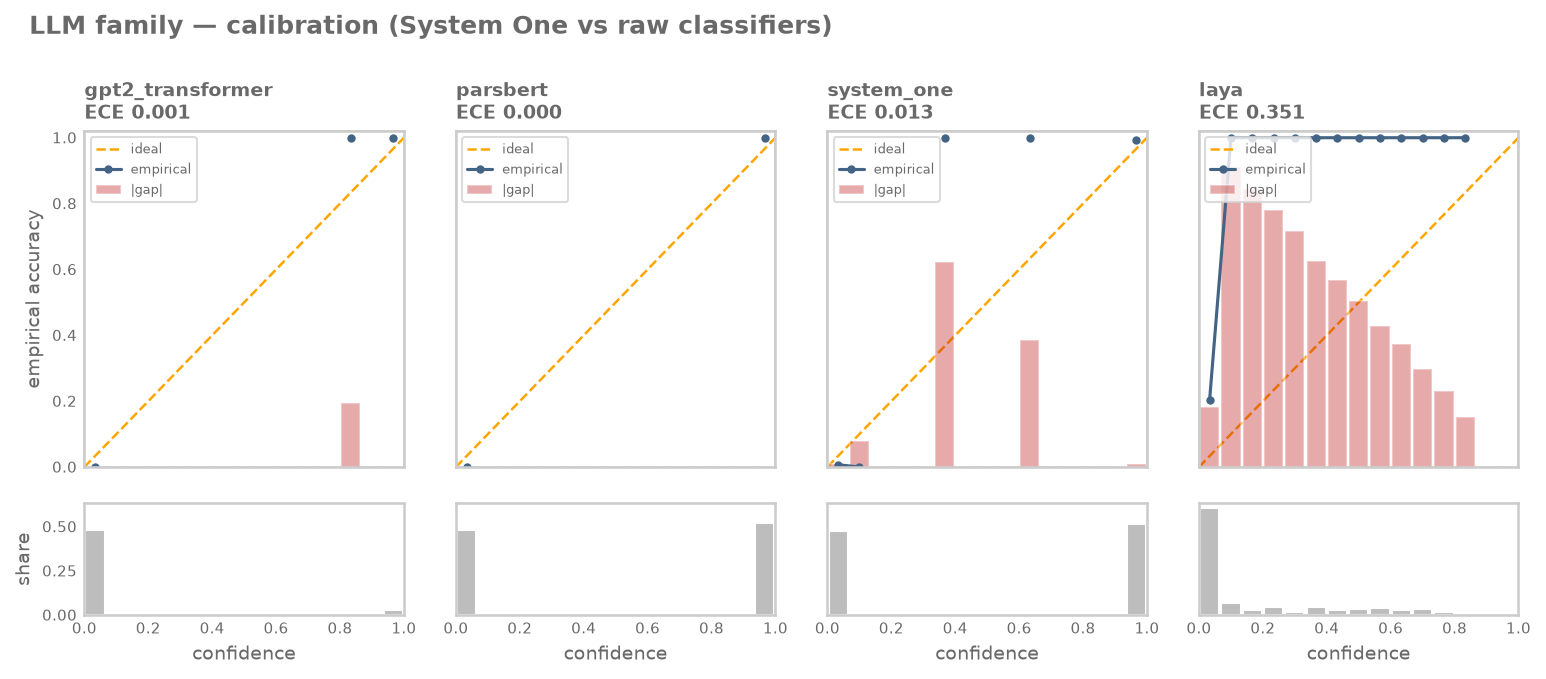

In [15]:
plots.reliability_grid(y_eval, probs_held, title="LLM family — calibration (System One vs raw classifiers)")

<Axes: title={'left': 'gpt2_transformer'}, xlabel='AI probability', ylabel='density'>

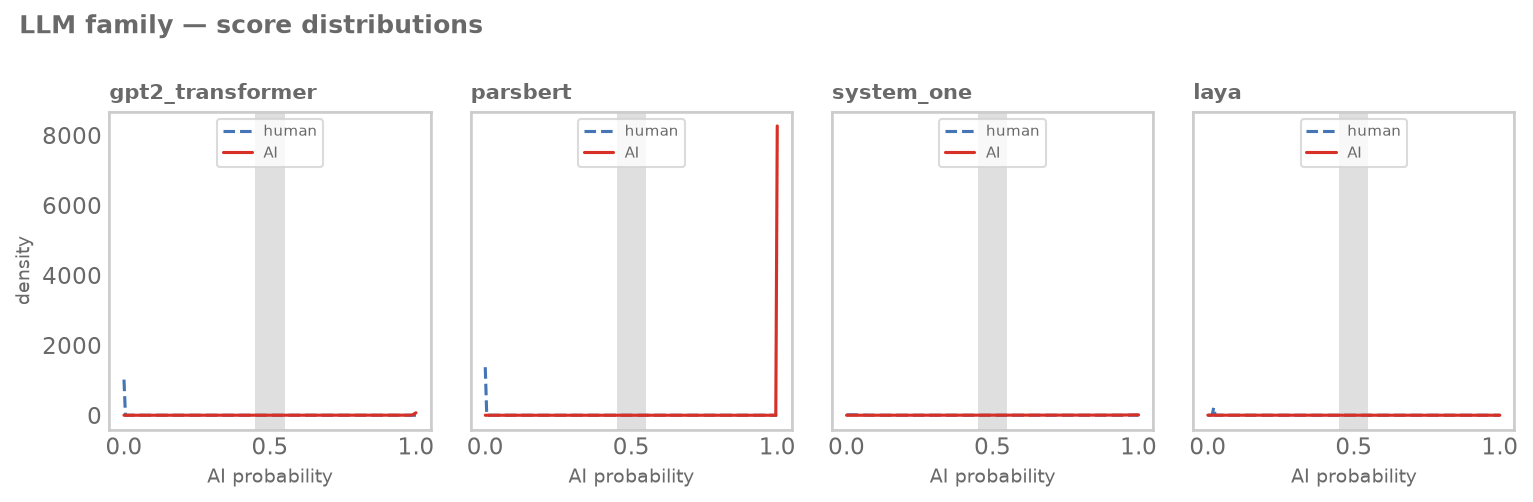

In [16]:
plots.score_distributions(y_eval, probs_held, "LLM family — score distributions")

## Summary

- Serving-path evaluation keeps every number bit-compatible with the deployed
  API: same loaders, same predictors, same preprocessing.
- The calibration table + reliability grid is the System One story: its typed
  decision heads are meant to produce trustworthy probabilities where the raw
  classifiers are over-confident (slope far from 1).
- `SAMPLES` show the typed answers (choice / score / review) per model.